# NB02E — Does site-specific M2 fine-tuning help? (3-fold spatial CV)

**Question:** Can adaptation to local RGB/canopy characteristics improve a global M2 model, especially Yangambi?

**Scientific protocol:** Start with each *frozen NB02B global M2 fold checkpoint*, then fine-tune separately for Baego, MOS, Yangambi and Yoko **using training-site chips only from that fold**. The 15 m holdout buffers, 30 independent test circles and their reference labels remain unchanged. **Do not train on held-out circles**. The global M2 checkpoint was itself trained on all four sites' fold-training data, so this is *site-specific fine-tuning*, not leave-one-site-out external transfer.

**Locked pilot:** 6 epochs, AdamW learning rate 5e−5, batch 8, same masked BCE and original RGB; no illumination correction, postprocessing, thresholds or parameter sweep. Three folds × four sites = twelve modest fine-tunes, with independent resume checkpoints and per-site/fold progress. A single site's fine-tuning operates on its own fold-training chip subset, including that site's valid partial crowns and training-circle exhaustive labels. Evaluate only that site's held-out circles. No site may learn from its held-out labels.

**Speed/safety:** Reuse NB02B's cached native RGB training chips and frozen M2 checkpoint. **Fail fast** if missing, rather than rebuilding expensive imagery or retraining the global model. All outputs under `Outputs/V3/02E_site_adapt_M2/`; NB02B/02D untouched. Results are exploratory because the 30 test circles have been examined in prior experiments.


## 01 — Inputs and NB01 spatial folds


In [1]:
%pip -q install rasterio geopandas pyogrio shapely pandas matplotlib scikit-learn segmentation-models-pytorch
from pathlib import Path
import json, warnings, math, random, time
import numpy as np, pandas as pd, geopandas as gpd, rasterio, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from rasterio.windows import Window
from rasterio.features import rasterize
from shapely.geometry import box
from shapely.ops import unary_union
from shapely import make_valid
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import average_precision_score, roc_auc_score
from IPython.display import display
from google.colab import drive
if not Path('/content/drive/MyDrive').exists():drive.mount('/content/drive')
ROOT=next((p for p in [Path('/content/drive/MyDrive/Colab Notebooks/Musanga/Final'),
                         Path('/content/drive/MyDrive/Musanga/Final')] if p.is_dir()),None)
assert ROOT is not None
BASELINE=ROOT/'Outputs/V3/02B_spatial3fold_no_MOS34'
OUT=ROOT/'Outputs/V3/02E_site_adapt_M2';OUT.mkdir(parents=True,exist_ok=True)
REF=ROOT/'Outputs/V3/01_reference_data_no_MOS34'
A=json.loads((ROOT/'Outputs/V3/00_input_audit/00_input_manifest.json').read_text())
assert A.get('schema_version')=='v3_input_audit_5_nadine_circles'
assert A['exhaustive_annotations'].get('all_annotation_polygons_musanga') is True
assert int(A['exhaustive_annotations']['verified_exhaustive_circle_count'])==34
EXCLUDED_MOSAIC='Mos_3_4_transparent_mosaic_group1_georef.tif'
mosaics={m['file']:m for m in A['mosaics'] if m['file']!=EXCLUDED_MOSAIC}
splits=pd.read_csv(REF/'01_cv_window_manifest.csv')
links=pd.read_csv(REF/'01_circle_spatial_folds.csv')
repairs=pd.read_csv(REF/'01_geometry_repairs.csv')
assert links.circle_id.nunique()==30
assert links.groupby('site').circle_id.nunique().to_dict()=={'Baego':7,'MOS':11,'Yangambi':7,'Yoko':5}
assert links.circle_id.is_unique
assert len(mosaics)==5,[(k,v['site']) for k,v in mosaics.items()]
TEST_SITE='SPATIAL_CV'  # training includes all four sites
FOLD=0;SEED=20261016;CROP=256;EPOCHS=25;BATCH=8
MAX_PARTIAL_PER_MOSAIC=250
MAX_EXHAUSTIVE_PER_SITE=260
HOLDOUT_COUNTS={'Baego':1,'MOS':2,'Yangambi':2,'Yoko':2}
assert torch.cuda.is_available(),'Select Runtime > Change runtime type > GPU for the pilot.'
device='cuda';torch.manual_seed(SEED);np.random.seed(SEED);random.seed(SEED)
print('PRIMARY: 3-fold within-site CV, partial-only M1 vs added-exhaustive M2')
print('GPU',torch.cuda.get_device_name(0),'| fold',FOLD)
print('Train/val candidates:',splits[splits.cv_fold==FOLD].split.value_counts().to_dict())
print('Files:',ROOT,'| output:',OUT)




print('Mosaics:',[(name,m['site']) for name,m in mosaics.items()])


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.1 MB/s eta 0:00:00
Mounted at /content/drive
PRIMARY: 3-fold within-site CV, partial-only M1 vs added-exhaustive M2
GPU NVIDIA L4 | fold 0
Train/val candidates: {'train': 2253, 'val': 334}
Files: /content/drive/MyDrive/Colab Notebooks/Musanga/Final | output: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/02E_site_adapt_M2
Mosaics: [('Baego.tif', 'Baego'), ('Mos_1_2_transparent_mosaic_group1_georef.tif', 'MOS'), ('Mos_5_6_transparent_mosaic_group1_georef.tif', 'MOS'), ('Yangambi_georef.tif', 'Yangambi'), ('Yoko_kvo_georef.tif', 'Yoko')]


## 02 — Load annotations and ImageNet-pretrained ResNet18 U-Net

In [2]:
def pieces(g):
    if g.geom_type in ('Polygon','MultiPolygon'):return [g]
    if hasattr(g,'geoms'):return [p for q in g.geoms for p in pieces(q)]
    return []
def polygons(path):
    src=gpd.read_file(path);inds=[];shapes=[]
    for i,g in enumerate(src.geometry):
        if g is None or g.is_empty:continue
        if not g.is_valid:
            try:
                fixed=unary_union(pieces(make_valid(g)))
                change=abs(fixed.area-g.area)/max(fixed.area,g.area,1e-12)
                if change>(.01 if Path(path) in (Path(A['exhaustive_annotations']['complete_roi_boundaries']),Path(A['exhaustive_annotations']['positive_polygons']),Path(A['roi'])) else .05) or not fixed.is_valid:continue
                g=fixed
            except Exception:continue
        inds.append(i);shapes.append(g)
    x=src.iloc[inds].copy().reset_index(drop=True)
    x.geometry=shapes
    x['original_row']=inds
    return x
roi=polygons(A['roi'])
circles=polygons(A['exhaustive_annotations']['complete_roi_boundaries'])
positive=polygons(A['exhaustive_annotations']['positive_polygons'])
assert len(circles)==34 and len(positive)>0, (
    f'Unexpected reference geometries: circles={len(circles)} (expected 34), '
    f'Musanga polygons={len(positive)}; do not train until reconciled')
circle_ids=set(links.circle_id.astype(int))
circles=circles[circles.original_row.isin(circle_ids)].copy()
tree={}
for site,path in A['shared_annotations'].items():
    t=polygons(path)
    cls=pd.to_numeric(t.Class_ID,errors='coerce')
    t['class01']=np.where(cls.eq(1),1,np.where(cls.notna(),0,-1))
    tree[site]=t
geo={}
for name,m in mosaics.items():
    with rasterio.open(m['path']) as src:
        c=circles.to_crs(src.crs).copy()
        c['fold']=c.original_row.map(links.set_index('circle_id').fold)
        c['owner']=c.original_row.map(links.set_index('circle_id').mosaic)
        geo[name]=dict(site=m['site'],path=m['path'],transform=src.transform,
            crs=src.crs,roi=roi.to_crs(src.crs),
            circles=c,positive=positive.to_crs(src.crs),trees=tree[m['site']].to_crs(src.crs))



In [3]:
class ResNet18UNet(nn.Module):
    """Original main-branch U-Net: ImageNet-pretrained ResNet18 encoder, RGB in, 1 logit out."""
    def __init__(self):
        super().__init__()
        import segmentation_models_pytorch as smp
        self.net=smp.Unet(encoder_name='resnet18',encoder_weights='imagenet',
                          in_channels=3,classes=1)
    def forward(self,x):
        return self.net(x)[:,0]

class CropData(Dataset):
    def __init__(self,rows,augment=False):self.rows=rows;self.augment=augment
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        d=self.rows[i];image=d['rgb'];y=d['y'];w=d['w']
        if self.augment:
            rng=np.random.default_rng(SEED+i+int(torch.randint(0,1000000,(1,)).item()))
            k=int(rng.integers(4));image=np.rot90(image,k);y=np.rot90(y,k);w=np.rot90(w,k)
            if rng.random()<.5:image=image[:,::-1];y=y[:,::-1];w=w[:,::-1]
        x=torch.tensor(np.ascontiguousarray(image.transpose(2,0,1)),dtype=torch.float32)
        return x,torch.tensor(np.ascontiguousarray(y)),torch.tensor(np.ascontiguousarray(w))
def masked_loss(logits,y,w):
    loss=F.binary_cross_entropy_with_logits(logits,y,reduction='none')
    return (loss*w).sum()/w.sum().clamp_min(1.)
print('ResNet18 U-Net ready (native 256×256 RGB crops).')




ResNet18 U-Net ready (native 256×256 RGB crops).


## 03 — Per-fold spatial exclusion (reconfigured for each training fold)

Use NB01 circle assignments, not site holdouts. Training crop footprint must not intersect any validation circle plus 15 m, across both MOS mosaics.


In [4]:
assert links.groupby(['site','fold']).circle_id.nunique().ge(1).all()
assert sorted(links.fold.unique().astype(int).tolist())==[0,1,2]
HOLDOUT=set();DEV=set();BLOCKED={}
split_df=links.iloc[:0].copy()
print('NB01 circle folds:',links.groupby(['site','fold']).size().unstack(fill_value=0).to_dict())


NB01 circle folds: {0: {'Baego': 3, 'MOS': 5, 'Yangambi': 2, 'Yoko': 1}, 1: {'Baego': 2, 'MOS': 3, 'Yangambi': 3, 'Yoko': 1}, 2: {'Baego': 2, 'MOS': 3, 'Yangambi': 2, 'Yoko': 3}}


## 04 — Resumable caches and direct RGB window reads

Source data, 256-pixel crops, augmentation, model architecture, optimizer and 25-epoch training remain unchanged. Cache fingerprint incorporates fold, supervision type and training-label selection. Direct Drive window reads avoid full-mosaic transfers.


In [5]:
from rasterio.windows import Window
from torch.utils.data import Dataset,DataLoader
candidate=pd.read_csv(REF/'01_candidate_windows.csv')
candidate=candidate[candidate.mosaic.isin(mosaics)].copy()
all_circle_buffers={}
for name,d in geo.items():
    cs=circles.to_crs(d['crs'])
    all_circle_buffers[name]=[g.buffer(15.) for g in cs.geometry]
    d['dev_circles']=cs[cs.original_row.isin(DEV)]
    d['holdout_circles']=cs[cs.original_row.isin(HOLDOUT)]
    d['positive_local']=positive.to_crs(d['crs'])
    d['trees_local']=tree[d['site']].to_crs(d['crs'])
    d['tree_positive']=d['trees_local'].loc[d['trees_local'].class01==1]
    d['tree_negative']=d['trees_local'].loc[d['trees_local'].class01==0]
    d['roi_local']=roi.to_crs(d['crs'])

def burn_window(geometries,name,win):
    """Rasterize geometries intersecting a crop, using the spatial index.

    Accept GeoSeries OR GeoDataFrame; always iterate actual Shapely geometries,
    never GeoDataFrame column names.
    """
    d=geo[name]
    series=geometries.geometry if isinstance(geometries,gpd.GeoDataFrame) else geometries
    assert isinstance(series,gpd.GeoSeries),type(series)
    bb=box(*rasterio.windows.bounds(win,d['transform']))
    ids=series.sindex.query(bb,predicate='intersects')
    shape=(int(win.height),int(win.width))
    if len(ids)==0:return np.zeros(shape,dtype=bool)
    selected=series.iloc[ids]
    return rasterize(((g,1) for g in selected.values
                      if g is not None and not g.is_empty),
        out_shape=shape,transform=rasterio.windows.transform(win,d['transform']),
        fill=0,dtype='uint8').astype(bool)

_ACTIVE_RASTER=None
_ACTIVE_NAME=None

def rgb_for_window(name,win):
    if _ACTIVE_RASTER is not None and _ACTIVE_NAME==name:
        raw=_ACTIVE_RASTER.read([1,2,3],window=win,masked=True)
    else:
        with rasterio.open(geo[name]['path']) as ds:
            raw=ds.read([1,2,3],window=win,masked=True)
    valid=~np.any(np.ma.getmaskarray(raw),axis=0)
    a=raw.filled(0).astype('float32')
    valid &= np.any(a!=0,axis=0)&np.any(a!=255,axis=0)
    valid &= ~((a[0]==0)&(a[1]==0)&(a[2]==255))
    return np.clip(a/255.,0,1).transpose(1,2,0).astype('float32'),valid

def training_crop(rec,model):
    name=rec.mosaic;d=geo[name]
    if rec.height<CROP or rec.width<CROP:return None
    rr=int(rec.row)+(int(rec.height)-CROP)//2
    cc=int(rec.col)+(int(rec.width)-CROP)//2
    win=Window(cc,rr,CROP,CROP)
    bb=box(*rasterio.windows.bounds(win,d['transform']))
    if any(bb.intersects(g) for g in BLOCKED[name]):return None
    if model=='M1' and any(bb.intersects(g) for g in all_circle_buffers[name]):return None
    if model=='M2' and rec.kind=='exhaustive' and int(rec.circle_id) not in DEV:return None
    inside=burn_window(d['roi_local'].geometry,name,win)
    pos_tree=burn_window(d['tree_positive'],name,win)
    neg_tree=burn_window(d['tree_negative'],name,win)
    if model=='M1':
        full=np.zeros_like(inside);pos_ex=np.zeros_like(inside)
    else:
        full=burn_window(d['dev_circles'].geometry,name,win)&inside
        pos_ex=burn_window(d['positive_local'].geometry,name,win)&full
    conflict=(pos_tree&neg_tree)| (pos_ex&neg_tree) | (full&~pos_ex&pos_tree)
    target=(pos_ex|(~full&pos_tree)).astype('float32')
    weight=(full|((pos_tree|neg_tree)&~full))&inside&~conflict
    img,valid=rgb_for_window(name,win)
    weight &= valid
    if int(weight.sum())<250:return None
    return dict(image=img,target=target,weight=weight.astype('float32'),
                site=d['site'],kind=rec.kind,mosaic=name)

def _pack_chips(path,items,signature):
    """Atomic, compressed uint8 cache of already-prepared chips."""
    if not items:return
    tmp=path.with_name(path.name+'.tmp.npz')
    try:
        np.savez_compressed(tmp,key=np.array(signature),
            rgb=np.stack([np.rint(np.clip(r['image'],0,1)*255).astype('uint8') for r in items]),
            target=np.stack([r['target'].astype('uint8') for r in items]),
            weight=np.stack([r['weight'].astype('uint8') for r in items]),
            site=np.array([r['site'] for r in items],dtype='U12'),
            kind=np.array([r['kind'] for r in items],dtype='U16'))
        tmp.replace(path)
    finally:
        tmp.unlink(missing_ok=True)

def _unpack_chips(path,signature):
    with np.load(path,allow_pickle=False) as z:
        assert str(z['key'].item())==signature
        rgb=z['rgb'];target=z['target'];weight=z['weight']
        sites=z['site'].astype(str);kinds=z['kind'].astype(str)
        assert rgb.ndim==4 and rgb.shape[1:]==(CROP,CROP,3)
        assert target.shape==weight.shape==rgb.shape[:3]
        return [dict(image=rgb[i].astype('float32')/255.,
                     target=target[i].astype('float32'),
                     weight=weight[i].astype('float32'),
                     site=str(sites[i]),kind=str(kinds[i]))
                for i in range(len(rgb))]

import shutil
from contextlib import contextmanager
LOCAL_STAGE=Path('/content/musanga_02f_stage')
LOCAL_STAGE.mkdir(parents=True,exist_ok=True)
MIN_FREE_AFTER_STAGE=2*1024**3
USE_LOCAL_STAGE=True

@contextmanager
def staged_mosaic(name):
    """Stage one raster on SSD if it fits; use one open raster handle per mosaic."""
    global _ACTIVE_RASTER,_ACTIVE_NAME
    source=Path(geo[name]['path'])
    assert source.exists(),source
    free=shutil.disk_usage('/content').free
    needed=source.stat().st_size
    local=LOCAL_STAGE/(name.replace('/','_'))
    can_stage=USE_LOCAL_STAGE and free>=needed+MIN_FREE_AFTER_STAGE
    selected_path=source
    if can_stage:
        print(f'STAGE {name}: {needed/1e9:.2f} GB from Drive to local SSD '
              f'(available {free/1e9:.1f} GB)',flush=True)
        t0=time.perf_counter()
        tmp=local.with_name(local.name+'.part')
        try:
            with source.open('rb') as inp,tmp.open('wb') as out:
                shutil.copyfileobj(inp,out,length=16*1024*1024)
            assert tmp.stat().st_size==needed
            tmp.replace(local)
            selected_path=local
            print(f'STAGED {name} in {time.perf_counter()-t0:.1f}s',flush=True)
        except Exception as exc:
            tmp.unlink(missing_ok=True)
            local.unlink(missing_ok=True)
            print(f'Local copy failed; using original Drive image: {exc}',flush=True)
    else:
        print(f'STAGE SKIPPED {name}: image {needed/1e9:.2f} GB, '
              f'free SSD {free/1e9:.2f} GB; using one persistent Drive handle',
              flush=True)
    assert _ACTIVE_RASTER is None,'Another mosaic is already open.'
    try:
        with rasterio.open(selected_path) as ds:
            assert ds.count>=3 and ds.transform==geo[name]['transform']
            assert ds.crs==geo[name]['crs']
            _ACTIVE_RASTER=ds
            _ACTIVE_NAME=name
            yield
    finally:
        _ACTIVE_RASTER=None
        _ACTIVE_NAME=None
        if selected_path==local:
            local.unlink(missing_ok=True)
            print(f'RELEASED local SSD for {name}',flush=True)

class CropDataset(Dataset):
    def __init__(self,rows):self.rows=rows
    def __len__(self):return len(self.rows)
    def __getitem__(self,i):
        q=self.rows[i];x=q['image'].copy();y=q['target'].copy();w=q['weight'].copy()
        k=int(torch.randint(0,4,(1,)).item())
        x=np.rot90(x,k);y=np.rot90(y,k);w=np.rot90(w,k)
        if torch.rand(1).item()<.5:x=x[:,::-1];y=y[:,::-1];w=w[:,::-1]
        return (torch.from_numpy(np.ascontiguousarray(x.transpose(2,0,1))),
                torch.from_numpy(np.ascontiguousarray(y)),torch.from_numpy(np.ascontiguousarray(w)))



# Training subsets are drawn only from the NB01 fold-specific manifest.
import hashlib

# CONTENT signatures, not just paths/mtime: modified shapefile geometry or DBF
# triggers a new M2 training key and *both* M1/M2 evaluation keys.
def shapefile_content_signature(source):
    p=Path(source)
    if not p.is_file():raise FileNotFoundError(p)
    files=sorted(p.parent.glob(p.stem+'.*')) if p.suffix.lower()=='.shp' else [p]
    files=([x for x in files if x.suffix.lower() in ('.shp','.shx','.dbf','.prj','.cpg')]
           if p.suffix.lower()=='.shp' else [p])
    h=hashlib.sha256()
    for file in files:
        h.update(file.suffix.lower().encode())
        with file.open('rb') as stream:
            for chunk in iter(lambda:stream.read(4*1024*1024),b''):
                h.update(chunk)
    return h.hexdigest()

EXHAUSTIVE_SOURCE=Path(A['exhaustive_annotations']['positive_polygons'])
EXHAUSTIVE_SHA=shapefile_content_signature(EXHAUSTIVE_SOURCE)
print('Exhaustive annotation SHA256:',EXHAUSTIVE_SHA[:20],
      '| polygons loaded:',len(positive),flush=True)

CACHE_DIR=BASELINE/'chip_cache'
CACHE_DIR.mkdir(parents=True,exist_ok=True)
def cv_fingerprint(fold,model_type):
    sources=[REF/'01_cv_window_manifest.csv',REF/'01_circle_spatial_folds.csv',
             REF/'01_candidate_windows.csv',ROOT/'Outputs/V3/00_input_audit/00_input_manifest.json']
    for name in sorted(mosaics):
        sources.append(Path(mosaics[name]['path']))
    deps=[(str(p),p.stat().st_size,p.stat().st_mtime_ns) for p in sources]
    payload=dict(version='spatial3fold_v2',fold=int(fold),model=model_type,
                 holdout=sorted(HOLDOUT),dev=sorted(DEV),crop=CROP,seed=SEED,
                 max_partial=MAX_PARTIAL_PER_MOSAIC,
                 max_exhaustive=MAX_EXHAUSTIVE_PER_SITE,buffer_m=15,files=deps,
                 exhaustive_annotations_sha256=EXHAUSTIVE_SHA if model_type=='M2' else None)
    return hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()

def make_cv_cache(model_type,fold):
    key=cv_fingerprint(fold,model_type)
    cache_file=CACHE_DIR/f'{model_type}_fold{fold}_{key[:20]}.npz'
    if cache_file.exists():
        try:
            old=_unpack_chips(cache_file,key)
            assert len(old)>15
            assert all(x['kind']=='partial' for x in old) if model_type=='M1' else True
            print('CACHE HIT',model_type,'fold',fold,len(old),'chips',flush=True)
            return old
        except Exception as e:
            print('Invalid full cache, rebuilding:',repr(e),flush=True)
            cache_file.unlink(missing_ok=True)
    # Same NB01 train candidate windows for both models, with exhaustive windows
    # added exclusively in M2; validation-fold windows are never eligible.
    eligible=splits[(splits.cv_fold==fold)&(splits.split=='train')].copy()
    eligible=eligible[eligible.kind.isin(['partial'] if model_type=='M1' else ['partial','exhaustive'])]
    if model_type=='M2':
        eligible=eligible[(eligible.kind=='partial')|eligible.circle_id.isin(DEV)]
    chosen=[]
    for (name,kind),group in eligible.groupby(['mosaic','kind']):
        cap=MAX_PARTIAL_PER_MOSAIC*(3 if geo[name]['site']=='MOS' else 1) if kind=='partial' else MAX_EXHAUSTIVE_PER_SITE
        group=group.sample(n=min(cap,len(group)),random_state=SEED)
        chosen.append(group)
    assert chosen,'No CV training windows'
    selected=pd.concat(chosen,ignore_index=True)
    assert not selected[selected.kind=='exhaustive'].circle_id.isin(HOLDOUT).any()
    print(model_type,'fold',fold,'selected windows:',selected.groupby(['site','kind']).size().to_dict(),flush=True)
    parts_dir=CACHE_DIR/f'{model_type}_fold{fold}_{key[:20]}'
    parts_dir.mkdir(parents=True,exist_ok=True)
    all_chips=[]
    for name,grp in selected.groupby('mosaic',sort=True):
        records=list(grp.itertuples(index=False))
        with staged_mosaic(name):
            for off in range(0,len(records),100):
                part=parts_dir/f'{name}_{off:04d}.npz'
                if part.exists():
                    try:
                        chunks=_unpack_chips(part,key)
                        all_chips.extend(chunks)
                        continue
                    except Exception:
                        part.unlink(missing_ok=True)
                items=[x for row in records[off:off+100] if (x:=training_crop(row,model_type)) is not None]
                if items:_pack_chips(part,items,key)
                all_chips.extend(items)
                print(model_type,'fold',fold,name,min(off+100,len(records)),'/',len(records),'usable',len(items),flush=True)
    assert len(all_chips)>15,(model_type,fold,len(all_chips))
    assert all(chip['kind']=='partial' for chip in all_chips) if model_type=='M1' else True
    _pack_chips(cache_file,all_chips,key)
    print('CACHE SAVED',model_type,'fold',fold,len(all_chips),'chips',flush=True)
    return all_chips


Exhaustive annotation SHA256: c28311cd143d67dda820 | polygons loaded: 1394


## 05 — Identical training recipe for M1 and M2; three spatial folds


In [6]:
import time
from contextlib import nullcontext
USE_AMP=(device=='cuda')
# float16 is fast on both T4 and L4; BCE is evaluated in fp32 for stability.
scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
print('CUDA mixed precision:',USE_AMP,'| GPU:',torch.cuda.get_device_name(0),flush=True)


def fit_cv(model_type,fold):
    fold_out=BASE_OUT/f'fold_{fold}'
    fold_out.mkdir(parents=True,exist_ok=True)
    key=cv_fingerprint(fold,model_type)
    # Versioned M2 models cannot silently reuse old Yangambi labels.
    # M1 uses partial labels only. Reuse the original completed M1 checkpoint
    # under the explicit assumption that only exhaustive POSITIVE polygons changed.
    legacy_m1=fold_out/f'fold_{fold}'/'M1_resnet18_spatialCV.pt'
    ckpt=(legacy_m1 if model_type=='M1' and legacy_m1.exists() else
          fold_out/f'M1_resnet18_spatialCV.pt' if model_type=='M1' else
          fold_out/f'M2_resnet18_spatialCV_{key[:20]}.pt')
    torch.manual_seed(SEED)
    model=ResNet18UNet().to(device)
    if ckpt.exists():
        model.load_state_dict(torch.load(ckpt,map_location=device,weights_only=True))
        print('Reusing spatial-CV checkpoint:',ckpt,flush=True)
        if model_type=='M1':
            print('M1 reuse assumes partial tree annotations, circle boundaries, '
                  'fold allocation and ROI unchanged.',flush=True)
        return model.eval()
    chips=make_cv_cache(model_type,fold)
    loader=DataLoader(CropDataset(chips),batch_size=BATCH,shuffle=True,num_workers=0,pin_memory=True)
    optim=torch.optim.AdamW(model.parameters(),lr=2e-4,weight_decay=1e-4)
    local_scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
    history=[]
    for ep in range(EPOCHS):
        model.train();losses=[];started=time.perf_counter()
        for x,y,w in loader:
            x=x.to(device,non_blocking=True);y=y.to(device,non_blocking=True);w=w.to(device,non_blocking=True)
            optim.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',dtype=torch.float16,enabled=USE_AMP):
                logits=model(x)
            loss=masked_loss(logits.float(),y,w)
            local_scaler.scale(loss).backward()
            local_scaler.step(optim);local_scaler.update()
            losses.append(float(loss.detach()))
        avg=float(np.mean(losses))
        history.append(dict(epoch=ep+1,masked_BCE=avg,seconds=time.perf_counter()-started))
        pd.DataFrame(history).to_csv(fold_out/f'{model_type}_loss.csv',index=False)
        print(f'{model_type} fold {fold} epoch {ep+1:02d}/{EPOCHS} BCE={avg:.4f} {history[-1]["seconds"]:.1f}s',flush=True)
    torch.save(model.state_dict(),ckpt)
    del chips
    print('Saved:',ckpt,flush=True)
    return model.eval()


CUDA mixed precision: True | GPU: NVIDIA L4


## 06 — Original RGB independent-circle scoring (same method as NB02B)


In [7]:
from scipy.special import expit,logit
from scipy.optimize import minimize
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
WINDOWS=pd.read_csv(REF/'01_candidate_windows.csv')
VAL_WINDOWS=WINDOWS[WINDOWS.kind=='exhaustive'].copy()
VAL_WINDOWS=VAL_WINDOWS[VAL_WINDOWS.circle_id.isin(links.circle_id)].copy()
assert set(VAL_WINDOWS.circle_id.unique().astype(int))==set(links.circle_id.astype(int))
N_BINS=256
BINS=np.linspace(0,1,N_BINS+1)
BIN_CENTER=(BINS[:-1]+BINS[1:])/2

def run_all_circles(model,model_name):
    statfile=OUT/f'{model_name}_spatialCV_circle_raw_{EVAL_KEY[:20]}.csv'
    histfile=OUT/f'{model_name}_spatialCV_histograms_{EVAL_KEY[:20]}.npz'
    if statfile.exists() and histfile.exists():
        return pd.read_csv(statfile),dict(np.load(histfile))
    model.eval();rows=[];histograms={}
    for _,circle in split_df.iterrows():
        cid=int(circle.circle_id)
        name=circle.mosaic
        d=geo[name]
        windows=VAL_WINDOWS[(VAL_WINDOWS.circle_id==cid)&(VAL_WINDOWS.mosaic==name)]
        assert len(windows),f'No evaluation windows for circle {cid}'
        cg=circles[circles.original_row==cid].to_crs(d['crs'])
        counts=np.zeros(N_BINS,np.int64);true_counts=np.zeros(N_BINS,np.int64)
        n=0;sumy=0.;sump=0.;sum_sq=0.;tp=fp=fn=tn=0
        rng=np.random.default_rng(SEED+cid)
        sample_truth=[];sample_probs=[]
        for rec in windows.itertuples(index=False):
            win=Window(int(rec.col),int(rec.row),int(rec.width),int(rec.height))
            mask=burn_window(cg.geometry,name,win)
            mask &= burn_window(d['roi_local'].geometry,name,win)
            rgb,valid=rgb_for_window(name,win)
            mask &= valid
            if not mask.any():continue
            reference=burn_window(d['positive_local'].geometry,name,win)
            x=torch.from_numpy(rgb.transpose(2,0,1).copy())[None].to(device)
            with torch.inference_mode():
                pred=torch.sigmoid(model(x))[0].cpu().numpy()
            y=reference[mask].astype('uint8');p=pred[mask].astype('float32')
            n+=len(y);sumy+=float(y.sum());sump+=float(p.sum())
            sum_sq+=float(np.square(p-y).sum())
            binary=p>=.5
            tp+=int(np.sum(binary&(y==1)));fp+=int(np.sum(binary&(y==0)))
            fn+=int(np.sum((~binary)&(y==1)))
            tn+=int(np.sum((~binary)&(y==0)))
            ix=np.minimum((p*N_BINS).astype(np.int32),N_BINS-1)
            counts+=np.bincount(ix,minlength=N_BINS).astype('int64')
            true_counts+=np.bincount(ix,weights=y,minlength=N_BINS).astype('int64')
            # only diagnostic AUC/AP uses pixel subsampling, with fixed per-circle cap
            take=rng.choice(len(y),min(100,len(y)),replace=False)
            sample_truth.extend(y[take].tolist());sample_probs.extend(p[take].tolist())
        assert n>0,f'No valid ROI/RGB reference pixels for circle {cid}'
        assert int(counts.sum())==n
        yt=np.asarray(sample_truth);pr=np.asarray(sample_probs)
        rows.append(dict(model=model_name,circle_id=cid,site=circle.site,split=circle.split,
                         valid_pixels=n,observed_fraction=100*sumy/n,
                         predicted_fraction=100*sump/n,
                         bias_pp=100*(sump-sumy)/n,brier=sum_sq/n,
                         f1_threshold_05=2*tp/max(1,2*tp+fp+fn),
                         tp=tp,fp=fp,fn=fn,tn=tn,
                         iou_threshold_05=tp/max(1,tp+fp+fn),
                         precision_threshold_05=tp/max(1,tp+fp),
                         recall_threshold_05=tp/max(1,tp+fn),
                         auc_sample=roc_auc_score(yt,pr) if len(np.unique(yt))>1 else np.nan,
                         ap_sample=average_precision_score(yt,pr) if len(np.unique(yt))>1 else np.nan))
        histograms[str(cid)+'_count']=counts
        histograms[str(cid)+'_positive']=true_counts
        print(model_name,'circle',cid,'obs',round(100*sumy/n,1),
              'pred',round(100*sump/n,1),'valid pixels',n,flush=True)
    frame=pd.DataFrame(rows)
    assert frame.circle_id.is_unique
    assert set(frame.circle_id.astype(int))==set(split_df.circle_id.astype(int))
    assert len(frame)==len(split_df)
    frame.to_csv(statfile,index=False)
    np.savez_compressed(histfile,**histograms)
    return frame,histograms



## 07 — Site-specific adaptation, three-fold evaluation, and paired reporting

Frozen baseline M2 training keys are verified against current source fingerprints. Site-specific adaptation uses **only** the cached fold-training chips for the target site, without touching other site-specific heldout circles. The original full-fold global checkpoint stays immutable.


In [8]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
import hashlib, json, gc, time
SITES=['Baego','MOS','Yangambi','Yoko']
FOLDS=[0,1,2]
FT_EPOCHS=6
FT_LR=5e-5
FT_WEIGHT_DECAY=1e-4
FT_BATCH=8
BASE_OUT=OUT
version_file=BASELINE/'02B_latest_reference_version.json'
assert version_file.exists(),f'Run NB02B first: {version_file}'
base_version=json.loads(version_file.read_text())
assert base_version['sha256']==EXHAUSTIVE_SHA,(
    'Different annotations: NB02B and NB02E references must match')
baseline_csv=BASELINE/'02B_spatialCV_all30_paired.csv'
assert baseline_csv.exists(),baseline_csv
BASELINE_M2=pd.read_csv(baseline_csv).query("model == 'M2'").copy()
assert len(BASELINE_M2)==30 and BASELINE_M2.circle_id.is_unique
assert set(BASELINE_M2.circle_id.astype(int))==set(links.circle_id.astype(int))

def _fingerprint_site(fold,site,global_key):
    return hashlib.sha256(json.dumps(dict(
        experiment='NB02E_site_specific_M2_v1',
        source_global_checkpoint=global_key,
        annotations_sha=EXHAUSTIVE_SHA,
        site=site,fold=fold,
        epochs=FT_EPOCHS,lr=FT_LR,wd=FT_WEIGHT_DECAY,batch=FT_BATCH,
        seed=SEED),sort_keys=True).encode()).hexdigest()

ALL_E=[]
for fold in FOLDS:
    FOLD=int(fold)
    HOLDOUT=set(links.loc[links.fold==FOLD,'circle_id'].astype(int))
    DEV=set(links.loc[links.fold!=FOLD,'circle_id'].astype(int))
    assert HOLDOUT.isdisjoint(DEV) and len(HOLDOUT|DEV)==30
    for name,d in geo.items():
        cs=circles.to_crs(d['crs'])
        d['dev_circles']=cs[cs.original_row.isin(DEV)]
        BLOCKED[name]=[g.buffer(15) for g in cs[cs.original_row.isin(HOLDOUT)].geometry]
    global_key=cv_fingerprint(FOLD,'M2')
    ckpt_global=BASELINE/f'fold_{FOLD}'/f'M2_resnet18_spatialCV_{global_key[:20]}.pt'
    cache_file=CACHE_DIR/f'M2_fold{FOLD}_{global_key[:20]}.npz'
    # Explicitly prevent silent full-model retraining / large reprocessing.
    assert ckpt_global.exists(),('Frozen global M2 checkpoint not found. '
        'Do NOT initiate new training until source identity is resolved.',ckpt_global)
    assert cache_file.exists(),('NB02B chip cache missing. '
        'Do NOT rebuild imagery without inspecting existing source fingerprints.',cache_file)
    chips=_unpack_chips(cache_file,global_key)
    print('\nFOLD',FOLD,'global checkpoint',ckpt_global.name,
          '| cached original RGB chips:',len(chips),flush=True)
    for site in SITES:
        split_df=links[(links.fold==FOLD)&(links.site==site)][
            ['circle_id','site','mosaic','cover_pct']].copy()
        assert len(split_df)>=1
        split_df['split']='held_out_spatial_fold'
        assert set(split_df.circle_id.astype(int)).issubset(HOLDOUT)
        train_site=[x for x in chips if x['site']==site]
        assert len(train_site)>=20,('Too few site chips',fold,site,len(train_site))
        assert sum(x['kind']=='exhaustive' for x in train_site)>0,(
            'No independent training-circle exhaustive chips',fold,site)
        sig=_fingerprint_site(FOLD,site,global_key)
        OUT=BASE_OUT/f'fold_{FOLD}'/site
        OUT.mkdir(parents=True,exist_ok=True)
        adapted_ckpt=OUT/f'M2_site_{site}_{sig[:20]}.pt'
        EVAL_KEY=sig
        torch.manual_seed(SEED+FOLD)
        model=ResNet18UNet().to(device)
        if adapted_ckpt.exists():
            print('CHECKPOINT HIT',FOLD,site,adapted_ckpt.name,flush=True)
            model.load_state_dict(torch.load(adapted_ckpt,map_location=device,weights_only=True))
        else:
            model.load_state_dict(torch.load(ckpt_global,map_location=device,weights_only=True))
            optim=torch.optim.AdamW(model.parameters(),lr=FT_LR,weight_decay=FT_WEIGHT_DECAY)
            scaler=torch.amp.GradScaler('cuda',enabled=(device=='cuda'))
            loader=DataLoader(CropDataset(train_site),batch_size=FT_BATCH,
                              shuffle=True,num_workers=0,pin_memory=True)
            hist=[]
            for epoch in range(FT_EPOCHS):
                model.train();losses=[];tic=time.perf_counter()
                for x,y,w in loader:
                    x=x.to(device,non_blocking=True)
                    y=y.to(device,non_blocking=True)
                    w=w.to(device,non_blocking=True)
                    optim.zero_grad(set_to_none=True)
                    with torch.autocast(device_type='cuda',dtype=torch.float16,
                                        enabled=(device=='cuda')):
                        logits=model(x)
                    loss=masked_loss(logits.float(),y,w)
                    scaler.scale(loss).backward()
                    scaler.step(optim);scaler.update()
                    losses.append(float(loss.detach()))
                loss_epoch=float(np.mean(losses))
                hist.append(dict(epoch=epoch+1,masked_BCE=loss_epoch,
                                 seconds=time.perf_counter()-tic))
                pd.DataFrame(hist).to_csv(OUT/'02E_training_history.csv',index=False)
                print(f'M2 SITE fold {FOLD} {site} epoch {epoch+1}/{FT_EPOCHS}: '
                      f'BCE {loss_epoch:.4f} {hist[-1]["seconds"]:.1f}s',flush=True)
            torch.save(model.state_dict(),adapted_ckpt)
            (OUT/'02E_config.json').write_text(json.dumps(dict(
                site=site,fold=FOLD,training_chips=len(train_site),signature=sig,
                baseline_checkpoint=str(ckpt_global),reference_sha256=EXHAUSTIVE_SHA,
                epochs=FT_EPOCHS,lr=FT_LR,batch=FT_BATCH),indent=2))
            print('Checkpoint saved:',adapted_ckpt.name,flush=True)
        result,_=run_all_circles(model,'M2_site')
        assert len(result)==len(split_df)
        result['fold']=FOLD
        result['adaptation_site']=site
        ALL_E.append(result)
        pd.concat(ALL_E,ignore_index=True).to_csv(
            BASE_OUT/'02E_progress_site_adaptation.csv',index=False)
        print(f'COMPLETE fold {FOLD} site {site} heldout circles {len(result)}',flush=True)
        del model
        torch.cuda.empty_cache();gc.collect()
    del chips;gc.collect()

ADAPTED=pd.concat(ALL_E,ignore_index=True)
assert len(ADAPTED)==30 and ADAPTED.circle_id.is_unique
assert set(ADAPTED.circle_id.astype(int))==set(BASELINE_M2.circle_id.astype(int))
ADAPTED.to_csv(BASE_OUT/'02E_M2_site_adapt_30circles.csv',index=False)

raw=BASELINE_M2.set_index('circle_id').sort_index()
adapt=ADAPTED.set_index('circle_id').sort_index()
assert raw.index.equals(adapt.index)
assert (raw.site==adapt.site).all() and (raw.fold==adapt.fold).all()
assert np.array_equal(raw.valid_pixels.to_numpy(),adapt.valid_pixels.to_numpy()),(
    'Different valid pixels; cannot compare')
assert np.allclose(raw.observed_fraction,adapt.observed_fraction,atol=1e-5),(
    'Different reference fraction; cannot compare')
PAIRED=pd.DataFrame({'circle_id':raw.index,'site':raw.site.values,
    'fold':raw.fold.values,'observed_fraction':raw.observed_fraction.values,
    'global_fraction':raw.predicted_fraction.values,
    'site_fraction':adapt.predicted_fraction.values,
    'global_pixel_f1':raw.f1_threshold_05.values,
    'site_pixel_f1':adapt.f1_threshold_05.values})
PAIRED['global_abs_error_pp']=(PAIRED.global_fraction-PAIRED.observed_fraction).abs()
PAIRED['site_abs_error_pp']=(PAIRED.site_fraction-PAIRED.observed_fraction).abs()
PAIRED['gain_pp']=PAIRED.global_abs_error_pp-PAIRED.site_abs_error_pp
PAIRED.to_csv(BASE_OUT/'02E_paired_global_vs_site_all30.csv',index=False)

def metrics_02e(df,method,site):
    obs=df.observed_fraction.to_numpy()
    pred=df.predicted_fraction.to_numpy()
    tp,fp,fn=[float(df[c].sum()) for c in ('tp','fp','fn')]
    return dict(method=method,site=site,n=len(df),
        R2=r2_score(obs,pred) if len(df)>1 else np.nan,
        MAE_pp=mean_absolute_error(obs,pred),
        RMSE_pp=np.sqrt(mean_squared_error(obs,pred)),
        bias_pp=float(np.mean(pred-obs)),
        pixel_F1=2*tp/max(1,2*tp+fp+fn),
        pixel_IoU=tp/max(1,tp+fp+fn),
        pixel_precision=tp/max(1,tp+fp),
        pixel_recall=tp/max(1,tp+fn))
rows=[]
for method,frame in [('GLOBAL_M2',BASELINE_M2),('SITE_ADAPTED_M2',ADAPTED)]:
    for site in ['ALL']+SITES:
        subset=frame if site=='ALL' else frame[frame.site==site]
        rows.append(metrics_02e(subset,method,site))
SUMMARY=pd.DataFrame(rows)
SUMMARY.to_csv(BASE_OUT/'02E_site_adaptation_metrics.csv',index=False)
display(SUMMARY.round(4))
print('Site-adapted model reduced absolute error in',
      int((PAIRED.gain_pp>0).sum()),'of 30 heldout circles')
print('Outputs:',BASE_OUT)



FOLD 0 global checkpoint M2_resnet18_spatialCV_ded9fba8097e31b4c6f0.pt | cached original RGB chips: 1635


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

M2 SITE fold 0 Baego epoch 1/6: BCE 0.1595 4.1s
M2 SITE fold 0 Baego epoch 2/6: BCE 0.1219 1.5s
M2 SITE fold 0 Baego epoch 3/6: BCE 0.1318 1.5s
M2 SITE fold 0 Baego epoch 4/6: BCE 0.1566 1.5s
M2 SITE fold 0 Baego epoch 5/6: BCE 0.1217 1.5s
M2 SITE fold 0 Baego epoch 6/6: BCE 0.1286 1.5s
Checkpoint saved: M2_site_Baego_28c9ca44a70f3ff9440e.pt
M2_site circle 0 obs 71.1 pred 72.3 valid pixels 1911817
M2_site circle 1 obs 28.2 pred 32.4 valid pixels 1911832
M2_site circle 30 obs 3.7 pred 13.8 valid pixels 1911798
COMPLETE fold 0 site Baego heldout circles 3
M2 SITE fold 0 MOS epoch 1/6: BCE 0.2010 2.3s
M2 SITE fold 0 MOS epoch 2/6: BCE 0.1607 2.2s
M2 SITE fold 0 MOS epoch 3/6: BCE 0.1655 2.2s
M2 SITE fold 0 MOS epoch 4/6: BCE 0.1696 2.2s
M2 SITE fold 0 MOS epoch 5/6: BCE 0.1463 2.2s
M2 SITE fold 0 MOS epoch 6/6: BCE 0.1700 2.2s
Checkpoint saved: M2_site_MOS_5a5e48cf0fa1c419319c.pt
M2_site circle 7 obs 77.4 pred 68.0 valid pixels 782899
M2_site circle 8 obs 40.3 pred 31.1 valid pixels 78293

,method,site,n,R2,MAE_pp,RMSE_pp,bias_pp,pixel_F1,pixel_IoU,pixel_precision,pixel_recall
0,GLOBAL_M2,ALL,30,0.7735,8.5571,10.9351,1.8087,0.5419,0.3717,0.5757,0.5119
1,GLOBAL_M2,Baego,7,0.6458,10.1669,12.4649,-0.0823,0.7086,0.5487,0.7477,0.6734
2,GLOBAL_M2,MOS,11,0.8346,6.8514,9.4698,2.0786,0.7721,0.6288,0.7643,0.7800
3,GLOBAL_M2,Yangambi,7,-3.5319,12.1825,13.6242,2.3302,0.3363,0.2022,0.3763,0.3041
4,GLOBAL_M2,Yoko,5,0.8547,4.9802,6.5408,3.1324,0.6830,0.5186,0.6971,0.6695
5,SITE_ADAPTED_M2,ALL,30,0.6567,11.0055,13.4616,2.1081,0.5186,0.3501,0.4651,0.5860
6,SITE_ADAPTED_M2,Baego,7,0.8338,7.8182,8.5382,1.6521,0.7411,0.5887,0.7609,0.7223
7,SITE_ADAPTED_M2,MOS,11,0.5105,14.1116,16.2937,-2.7656,0.7149,0.5563,0.7515,0.6816
8,SITE_ADAPTED_M2,Yangambi,7,-5.1873,13.1021,15.9193,12.2235,0.3848,0.2382,0.3041,0.5238
9,SITE_ADAPTED_M2,Yoko,5,0.8425,5.6992,6.8091,-0.6927,0.6593,0.4917,0.7366,0.5967


Site-adapted model reduced absolute error in 14 of 30 heldout circles
Outputs: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3/02E_site_adapt_M2


## 08 — Paired plot of global versus site-adapted M2 errors


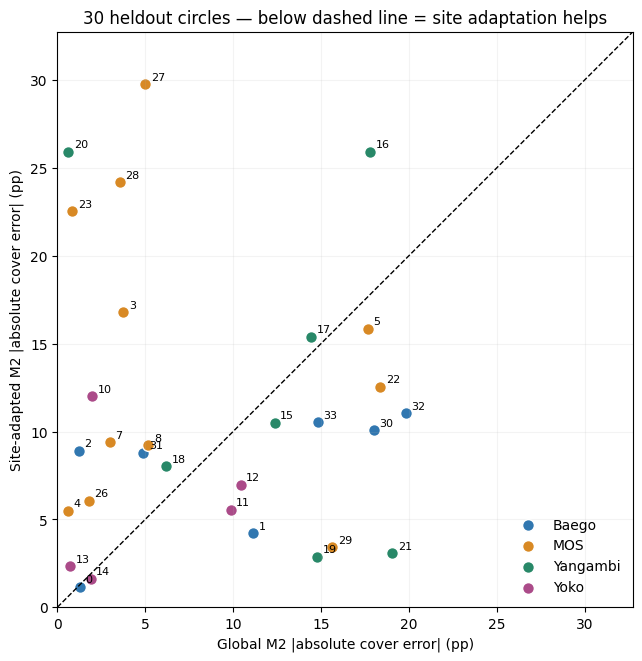

Site metrics:


,method,site,n,R2,MAE_pp,RMSE_pp,bias_pp,pixel_F1,pixel_IoU,pixel_precision,pixel_recall
0,GLOBAL_M2,ALL,30,0.773,8.557,10.935,1.809,0.542,0.372,0.576,0.512
1,GLOBAL_M2,Baego,7,0.646,10.167,12.465,-0.082,0.709,0.549,0.748,0.673
2,GLOBAL_M2,MOS,11,0.835,6.851,9.470,2.079,0.772,0.629,0.764,0.780
3,GLOBAL_M2,Yangambi,7,-3.532,12.182,13.624,2.330,0.336,0.202,0.376,0.304
4,GLOBAL_M2,Yoko,5,0.855,4.980,6.541,3.132,0.683,0.519,0.697,0.670
5,SITE_ADAPTED_M2,ALL,30,0.657,11.006,13.462,2.108,0.519,0.350,0.465,0.586
6,SITE_ADAPTED_M2,Baego,7,0.834,7.818,8.538,1.652,0.741,0.589,0.761,0.722
7,SITE_ADAPTED_M2,MOS,11,0.510,14.112,16.294,-2.766,0.715,0.556,0.752,0.682
8,SITE_ADAPTED_M2,Yangambi,7,-5.187,13.102,15.919,12.223,0.385,0.238,0.304,0.524
9,SITE_ADAPTED_M2,Yoko,5,0.842,5.699,6.809,-0.693,0.659,0.492,0.737,0.597


In [9]:
import matplotlib.pyplot as plt
FIG_DIR=BASE_OUT/'figures';FIG_DIR.mkdir(parents=True,exist_ok=True)
colors={'Baego':'#3177B0','MOS':'#D88924','Yangambi':'#288868','Yoko':'#AB4B89'}
fig,ax=plt.subplots(figsize=(7,6.5),layout='constrained')
maxerr=float(max(PAIRED.global_abs_error_pp.max(),PAIRED.site_abs_error_pp.max())+3)
for site in SITES:
    d=PAIRED[PAIRED.site==site]
    ax.scatter(d.global_abs_error_pp,d.site_abs_error_pp,
               label=site,c=colors[site],s=72,edgecolors='white')
    for q in d.itertuples():
        ax.annotate(str(int(q.circle_id)),
                    (q.global_abs_error_pp,q.site_abs_error_pp),
                    xytext=(4,3),textcoords='offset points',fontsize=8)
ax.plot([0,maxerr],[0,maxerr],'k--',lw=1)
ax.set(xlim=(0,maxerr),ylim=(0,maxerr),aspect='equal',
       xlabel='Global M2 |absolute cover error| (pp)',
       ylabel='Site-adapted M2 |absolute cover error| (pp)',
       title='30 heldout circles — below dashed line = site adaptation helps')
ax.legend(frameon=False);ax.grid(alpha=.15)
for ext in ('png','pdf'):fig.savefig(FIG_DIR/f'02E_site_adaptation_paired.{ext}',dpi=220,bbox_inches='tight')
plt.show();plt.close(fig)
print('Site metrics:');display(SUMMARY.round(3))
